# California House Price Prediction using Machine Learning

**AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 - BharatCares**

| | |
|---|---|
| **Author** | Himanshu Namdev |
| **Programme** | B.Tech Computer Science & Engineering (Final Year), Samrat Ashok Rajkiya Engineering College, Mirzapur (AKTU, Lucknow) |
| **Domain** | Data Analytics with AI |
| **Problem type** | Supervised learning - regression |
| **Dataset** | California Housing Prices (1990 US Census, 20,640 block groups) |

---

## 1. Introduction and objectives

Buying, selling, taxing and financing a home all depend on one number: its **price**. Estimating that number from
measurable characteristics - the neighbourhood's income level, the age and size of its housing stock, how crowded it is
and where it sits on the map - is a classic data-analytics problem and a natural fit for machine learning.

**Business question:** *Given the demographic, housing and location characteristics of a neighbourhood, can we predict its
median house value accurately enough to support pricing, investment and planning decisions - and which factors drive price the most?*

**Objectives**

1. Load, inspect and clean the dataset (missing values, censored values, outliers).
2. Explore the data visually and statistically to understand what drives house prices.
3. Engineer meaningful features (ratios and geographic distances).
4. Build a leak-free preprocessing + modelling **pipeline** and compare eight regression algorithms with cross-validation.
5. Tune the most promising models, evaluate the winner on a held-out test set, and analyse where it makes errors.
6. Interpret the model (permutation importance, partial dependence) and save it for reuse.

**Workflow:** Data loading -> Data understanding -> EDA -> Feature engineering -> Train/test split -> Preprocessing pipeline ->
Model comparison (5-fold CV) -> Hyper-parameter tuning -> Test evaluation -> Error analysis -> Interpretation -> Save & predict.

## 2. Setup - imports and configuration

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from matplotlib.ticker import FuncFormatter

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             median_absolute_error, r2_score)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Configuration -------------------------------------------------------------------------
RANDOM_STATE = 42          # fixed seed -> reproducible results
TARGET = "median_house_value"
DATA_FILE = Path("housing.csv")   # local copy (downloaded automatically if missing)
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
FIG_DIR = Path("figures")         # all charts are saved here (used in the project report)
OUT_DIR = Path("outputs")         # metrics, tables and the trained model are saved here
FAST_MODE = False                 # True -> fewer tuning iterations (about 3x faster, slightly less tuned)

FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
ACCENT, ACCENT2, MUTED = "#2F5D8C", "#E07B39", "#8A94A6"


USD = FuncFormatter(lambda v, _: f"${v:,.0f}")             # axis formatter: $1,234
USD_K = FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")   # axis formatter: $250k


def grid_on(ax, axis):
    """Keep grid lines only along one axis (cleaner bar charts)."""
    ax.grid(False)
    ax.grid(True, axis=axis)


def save_fig(name):
    """Save the current figure to ./figures and display it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 3. Load the dataset

The data is the **California Housing Prices** dataset (Pace & Barry, 1997; 1990 US Census), a standard regression benchmark.
Each row is a *block group* - the smallest geographical unit for which the Census publishes data (typically 600-3,000 people).

* Kaggle page: <https://www.kaggle.com/datasets/camnugent/california-housing-prices>
* Direct CSV used by this notebook: <https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv>

If `housing.csv` is not next to the notebook it is downloaded automatically.

In [2]:
if not DATA_FILE.exists():
    print("housing.csv not found locally - downloading ...")
    pd.read_csv(DATA_URL).to_csv(DATA_FILE, index=False)

df = pd.read_csv(DATA_FILE)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {DATA_FILE}")
display(df.head())

Loaded 20,640 rows x 10 columns from housing.csv


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 4. Data understanding and quality checks

| Column | Meaning |
|---|---|
| `longitude`, `latitude` | Location of the block group |
| `housing_median_age` | Median age of houses (years) |
| `total_rooms`, `total_bedrooms` | Total rooms / bedrooms across all houses in the block group |
| `population`, `households` | Residents / households in the block group |
| `median_income` | Median household income (in tens of thousands of US$) |
| `ocean_proximity` | Categorical distance from the ocean |
| **`median_house_value`** | **Target** - median house value (US$) |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


In [5]:
NUMERIC_RAW = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
               "population", "households", "median_income"]

# --- Missing values ---
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
print("Columns with missing values:")
display(missing[missing["missing_count"] > 0])

# --- Duplicates ---
print("Duplicate rows:", df.duplicated().sum())

# --- Censored (capped) values ---
cap_value = df[TARGET].max()
n_capped_target = int((df[TARGET] == cap_value).sum())
n_capped_age = int((df["housing_median_age"] == df["housing_median_age"].max()).sum())
print(f"Rows where the target is capped at {cap_value:,.0f}: {n_capped_target} ({n_capped_target / len(df):.1%})")
print(f"Rows where housing_median_age is capped at {df['housing_median_age'].max():.0f}: {n_capped_age} ({n_capped_age / len(df):.1%})")

# --- Outliers (IQR rule) ---
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

outlier_table = pd.DataFrame({"outliers (IQR rule)": {c: iqr_outliers(df[c].dropna()) for c in NUMERIC_RAW + [TARGET]}})
outlier_table["share_%"] = (outlier_table["outliers (IQR rule)"] / len(df) * 100).round(2)
print("\nOutlier summary:")
display(outlier_table)

Columns with missing values:


,missing_count,missing_pct
total_bedrooms,207,1.0


Duplicate rows: 0
Rows where the target is capped at 500,001: 965 (4.7%)
Rows where housing_median_age is capped at 52: 1273 (6.2%)

Outlier summary:


,outliers (IQR rule),share_%
longitude,0,0.00
latitude,0,0.00
housing_median_age,0,0.00
total_rooms,1287,6.24
total_bedrooms,1271,6.16
population,1196,5.79
households,1220,5.91
median_income,681,3.30
median_house_value,1071,5.19


**Findings and decisions**

* **Missing values** - only `total_bedrooms` has gaps. We will impute with the *median*, learned **on the training data only**
  inside the pipeline, so that no information leaks from the test set.
* **Censored values** - the survey capped `median_house_value` at 500,001 and `housing_median_age` at 52. These are real
  limitations of the data (the true values are higher). We keep the rows (dropping them would bias the sample towards cheaper
  areas) and later check how much they affect the results.
* **Outliers** - extreme values in `total_rooms`, `population` etc. correspond to very large block groups, not data-entry errors.
  We keep them; tree-based models are robust to them, and ratio features (below) normalise for size.
* **Duplicates** - none found.

## 5. Exploratory data analysis (EDA)

### 5.1 Distribution of the target variable

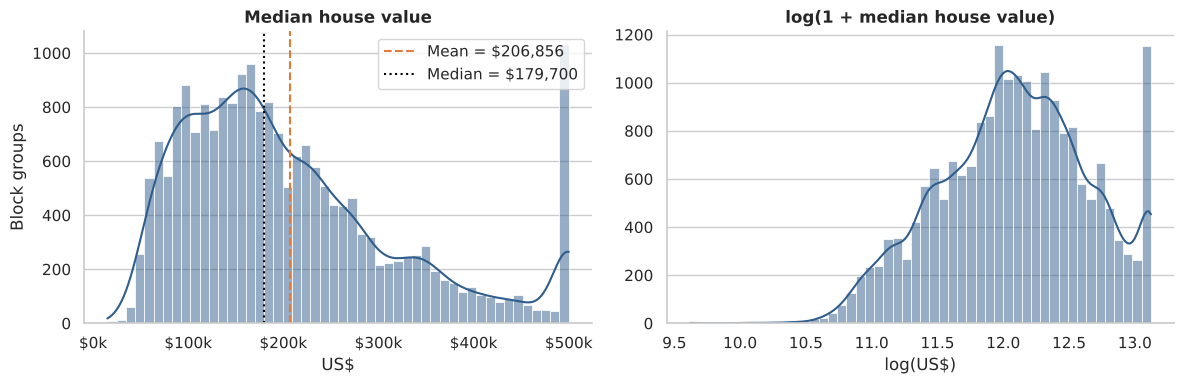

Skewness of target: 0.98  |  after log transform: -0.17


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, kde=True, color=ACCENT, ax=axes[0])
axes[0].axvline(df[TARGET].mean(), color=ACCENT2, ls="--", label=f"Mean = ${df[TARGET].mean():,.0f}")
axes[0].axvline(df[TARGET].median(), color="black", ls=":", label=f"Median = ${df[TARGET].median():,.0f}")
axes[0].set(title="Median house value", xlabel="US$", ylabel="Block groups")
axes[0].xaxis.set_major_formatter(USD_K)
axes[0].legend()
grid_on(axes[0], "y")
grid_on(axes[1], "y")
sns.histplot(np.log1p(df[TARGET]), bins=50, kde=True, color=ACCENT, ax=axes[1])
axes[1].set(title="log(1 + median house value)", xlabel="log(US$)", ylabel="")
save_fig("fig01_target_distribution")
print(f"Skewness of target: {df[TARGET].skew():.2f}  |  after log transform: {np.log1p(df[TARGET]).skew():.2f}")

### 5.2 Distribution of the input features

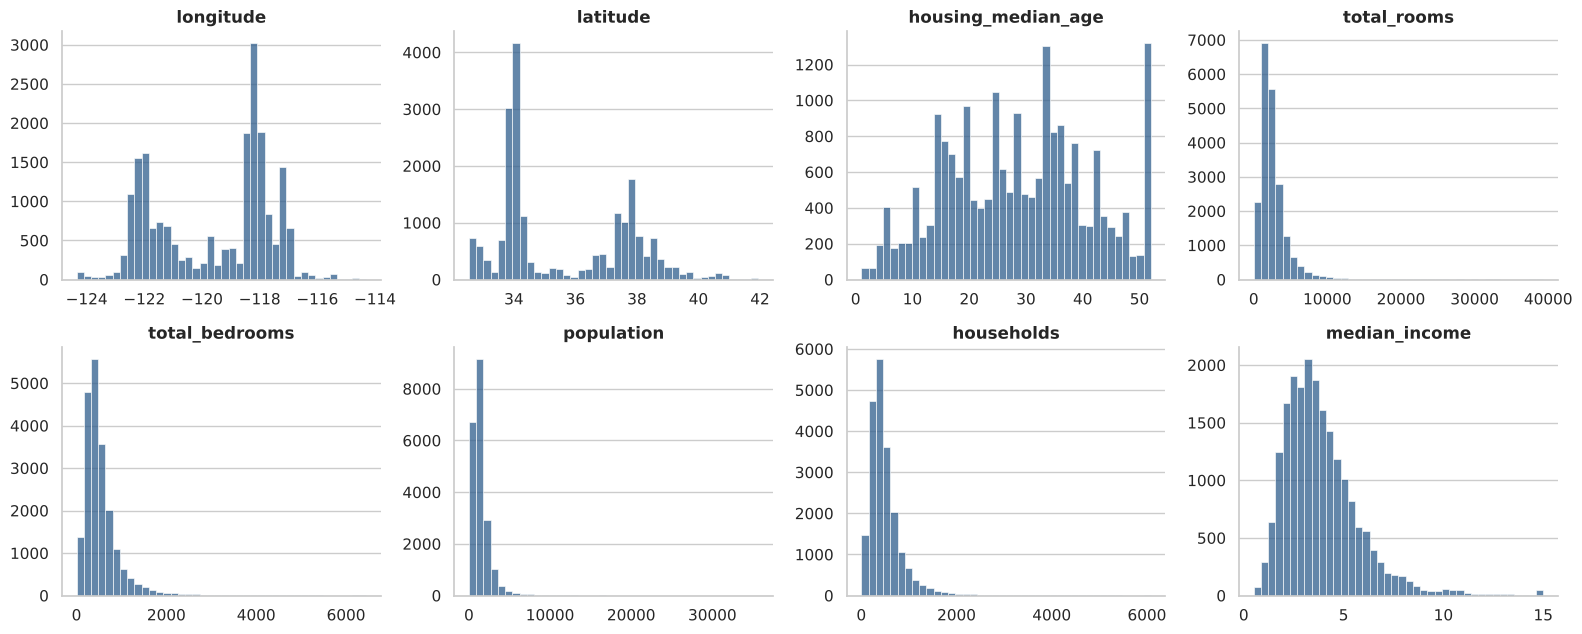

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), NUMERIC_RAW):
    sns.histplot(df[col].dropna(), bins=40, color=ACCENT, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
    grid_on(ax, "y")
save_fig("fig02_feature_histograms")

### 5.3 Where are the expensive neighbourhoods?
Plotting longitude against latitude draws the shape of California. Colour shows price, bubble size shows population.

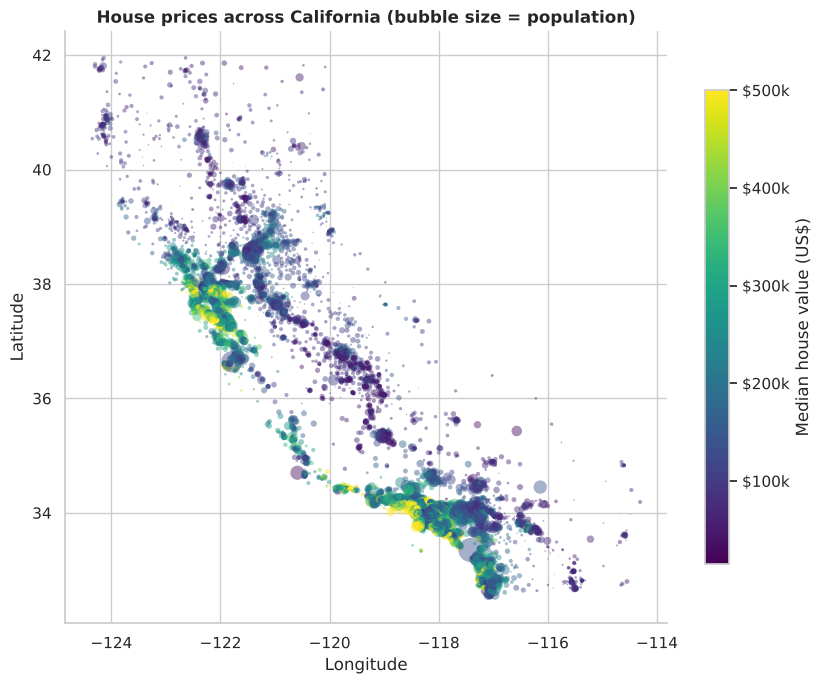

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 7))
sc = ax.scatter(df["longitude"], df["latitude"], c=df[TARGET], s=df["population"] / 120,
                cmap="viridis", alpha=0.45, linewidths=0)
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("Median house value (US$)")
cbar.solids.set(alpha=1)                    # keep the colour bar opaque although the points are transparent
cbar.ax.yaxis.set_major_formatter(USD_K)
ax.set(title="House prices across California (bubble size = population)", xlabel="Longitude", ylabel="Latitude")
save_fig("fig03_geographic_prices")

### 5.4 Correlation analysis

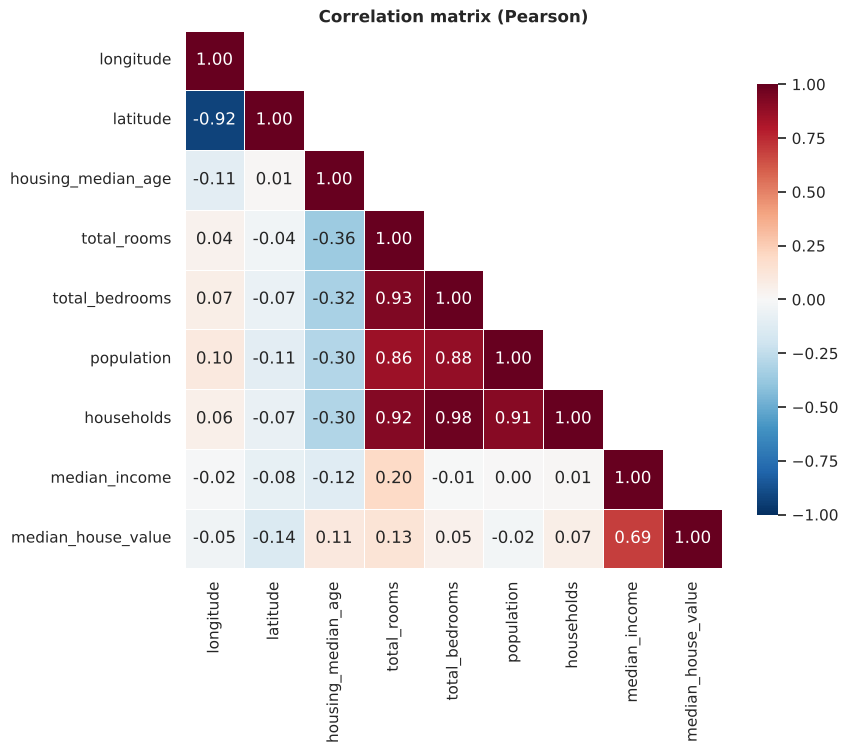

Correlation with the target (strongest first):
median_income         0.688
latitude             -0.144
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
longitude            -0.046
population           -0.025


In [9]:
corr = df[NUMERIC_RAW + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
ax.grid(False)
save_fig("fig04_correlation_heatmap")

target_corr = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
print("Correlation with the target (strongest first):")
print(target_corr.round(3).to_string())

### 5.5 Income vs price and the effect of ocean proximity

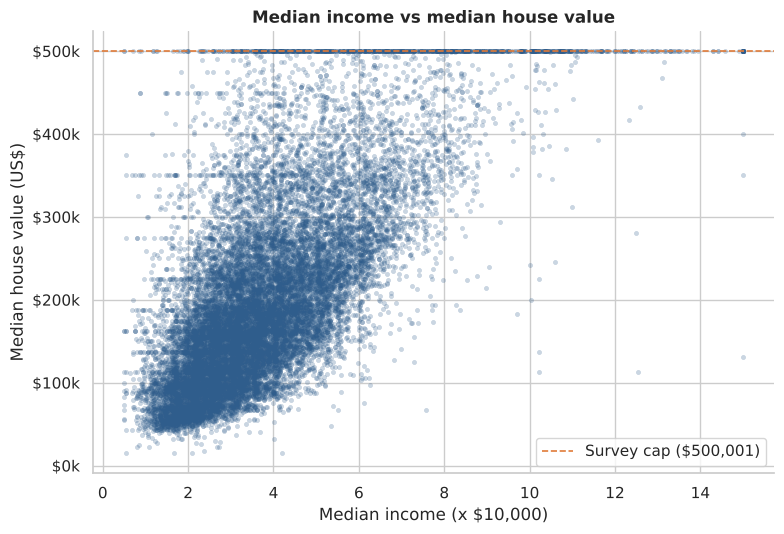

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="median_income", y=TARGET, alpha=0.25, s=10, color=ACCENT, edgecolor=None, ax=ax)
ax.axhline(cap_value, color=ACCENT2, ls="--", lw=1.2, label=f"Survey cap (${cap_value:,.0f})")
ax.set(title="Median income vs median house value", xlabel="Median income (x $10,000)", ylabel="Median house value (US$)")
ax.yaxis.set_major_formatter(USD_K)
ax.legend()
save_fig("fig05_income_vs_price")

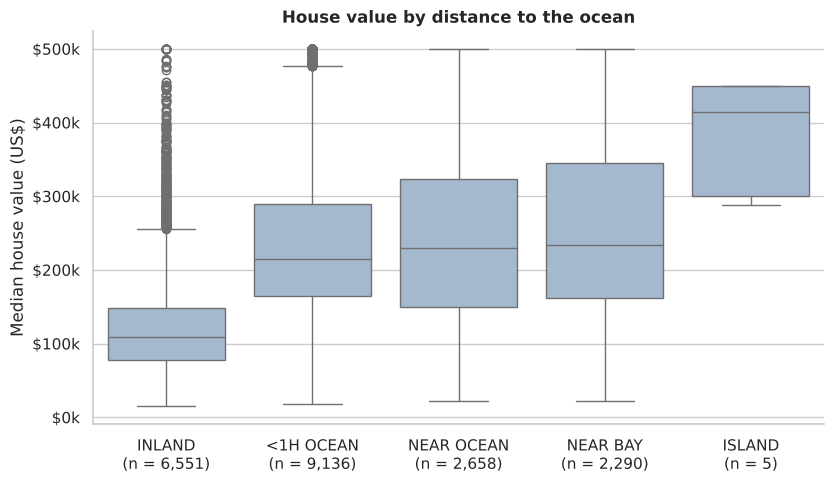

,count,mean,median
ocean_proximity,,,
INLAND,6551,124805.0,108500.0
<1H OCEAN,9136,240084.0,214850.0
NEAR OCEAN,2658,249434.0,229450.0
NEAR BAY,2290,259212.0,233800.0
ISLAND,5,380440.0,414700.0


In [11]:
order = df.groupby("ocean_proximity")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.boxplot(data=df, x="ocean_proximity", y=TARGET, order=order, color="#9DB7D5", ax=ax)
counts = df["ocean_proximity"].value_counts()
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{c}\n(n = {counts[c]:,})" for c in order])
ax.set(title="House value by distance to the ocean", xlabel="", ylabel="Median house value (US$)")
ax.yaxis.set_major_formatter(USD_K)
grid_on(ax, "y")
save_fig("fig06_price_by_ocean_proximity")
display(df.groupby("ocean_proximity")[TARGET].agg(["count", "mean", "median"]).loc[order].round(0))

In [12]:
# Dynamic summary of EDA insights (numbers are computed, not typed)
pct_corr_income = corr.loc["median_income", TARGET]
cheapest, priciest = order[0], order[-1]
med = df.groupby("ocean_proximity")[TARGET].median()
print("KEY EDA INSIGHTS")
print(f"1. The target is right-skewed (skew = {df[TARGET].skew():.2f}) and piles up at the ${cap_value:,.0f} cap.")
print(f"2. Median income is by far the strongest linear driver of price (r = {pct_corr_income:.2f}).")
print(f"3. Location matters: '{priciest}' blocks have a median value of ${med[priciest]:,.0f} versus ${med[cheapest]:,.0f} for '{cheapest}'.")
print(f"4. total_rooms, total_bedrooms, population and households are highly inter-correlated "
      f"(e.g. rooms vs bedrooms r = {corr.loc['total_rooms', 'total_bedrooms']:.2f}) - they mostly measure block-group size, "
      f"which motivates per-household ratio features.")

KEY EDA INSIGHTS
1. The target is right-skewed (skew = 0.98) and piles up at the $500,001 cap.
2. Median income is by far the strongest linear driver of price (r = 0.69).
3. Location matters: 'ISLAND' blocks have a median value of $414,700 versus $108,500 for 'INLAND'.
4. total_rooms, total_bedrooms, population and households are highly inter-correlated (e.g. rooms vs bedrooms r = 0.93) - they mostly measure block-group size, which motivates per-household ratio features.


**What the EDA tells us**

* Prices are right-skewed with a visible pile-up at the survey cap.
* **Income** is the single strongest predictor; the relationship is positive and roughly linear up to the cap.
* **Geography** is decisive - the map clearly shows expensive coastal clusters around the Bay Area and Los Angeles / San Diego,
  and cheaper inland areas. A model must therefore make good use of latitude / longitude.
* Raw count features (`total_rooms`, `population` ...) mainly reflect the *size* of the block group rather than the
  *quality* of housing, so ratios per household should be more informative.

## 6. Feature engineering

We create features that capture living conditions and geography. All of them are **row-wise deterministic formulas**
(no statistics are learned from the data), so computing them before the train/test split cannot leak information.

| New feature | Formula | Rationale |
|---|---|---|
| `rooms_per_household` | total_rooms / households | Average home size |
| `bedrooms_per_room` | total_bedrooms / total_rooms | Share of bedrooms; low values suggest bigger / more upscale homes |
| `population_per_household` | population / households | Crowding |
| `dist_<city>_km` (x5) | Haversine distance to Los Angeles, San Francisco, San Diego, San Jose, Sacramento | Proximity to major job markets |
| `dist_nearest_major_city_km` | min of the five distances | Overall urban accessibility |

Feature matrix: 20,640 rows x 18 columns (9 engineered)


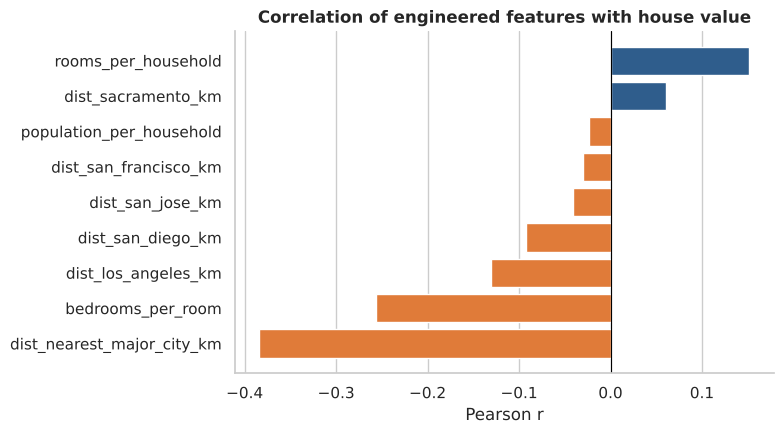

In [13]:
MAJOR_CITIES = {
    "los_angeles": (34.0522, -118.2437),
    "san_francisco": (37.7749, -122.4194),
    "san_diego": (32.7157, -117.1611),
    "san_jose": (37.3382, -121.8863),
    "sacramento": (38.5816, -121.4944),
}


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in kilometres between two points (vectorised)."""
    r = 6371.0088
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def add_features(data):
    """Return a copy of `data` (raw columns, no target) with the engineered features added."""
    out = data.copy()
    out["rooms_per_household"] = out["total_rooms"] / out["households"]
    out["bedrooms_per_room"] = out["total_bedrooms"] / out["total_rooms"]   # stays NaN where total_bedrooms is missing
    out["population_per_household"] = out["population"] / out["households"]
    dist_cols = []
    for city, (lat, lon) in MAJOR_CITIES.items():
        col = f"dist_{city}_km"
        out[col] = haversine_km(out["latitude"], out["longitude"], lat, lon)
        dist_cols.append(col)
    out["dist_nearest_major_city_km"] = out[dist_cols].min(axis=1)
    return out


NEW_FEATURES = ["rooms_per_household", "bedrooms_per_room", "population_per_household",
                "dist_los_angeles_km", "dist_san_francisco_km", "dist_san_diego_km",
                "dist_san_jose_km", "dist_sacramento_km", "dist_nearest_major_city_km"]

y = df[TARGET].copy()
X = add_features(df.drop(columns=[TARGET]))
print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} columns ({len(NEW_FEATURES)} engineered)")

# How do the new features relate to price?
new_corr = X[NEW_FEATURES].corrwith(y).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(new_corr.index, new_corr.values, color=[ACCENT if v > 0 else ACCENT2 for v in new_corr.values])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Correlation of engineered features with house value", xlabel="Pearson r")
grid_on(ax, "x")
save_fig("fig07_engineered_feature_correlation")

## 7. Train / test split

We hold out **20 %** of the data as a final test set that is never touched during model selection. The split is **stratified by
income category**, because income is the strongest predictor - this guarantees the test set has the same income mix as the
training set and makes the evaluation more reliable than a purely random split.

In [14]:
income_cat = pd.cut(df["median_income"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1, 2, 3, 4, 5])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=income_cat)

strat_check = pd.DataFrame({
    "full data": income_cat.value_counts(normalize=True).sort_index(),
    "train": income_cat.loc[X_train.index].value_counts(normalize=True).sort_index(),
    "test": income_cat.loc[X_test.index].value_counts(normalize=True).sort_index(),
}).mul(100).round(2)
strat_check.index.name = "income category"
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print("\nShare of each income category (%) - the split preserves the distribution:")
display(strat_check)

Train: 16,512 rows | Test: 4,128 rows

Share of each income category (%) - the split preserves the distribution:


,full data,train,test
income category,,,
1,3.98,3.98,4.00
2,31.88,31.89,31.88
3,35.06,35.06,35.05
4,17.63,17.63,17.64
5,11.44,11.45,11.43


## 8. Preprocessing pipeline

A scikit-learn `ColumnTransformer` applies the right treatment to each column type:

* **Numeric columns** -> median imputation -> standard scaling (needed by distance- and regularisation-based models; harmless for trees)
* **`ocean_proximity`** -> one-hot encoding (unknown categories are ignored at prediction time)

Everything is placed *inside* a `Pipeline` together with the model, so during cross-validation the imputer / scaler / encoder
are re-fitted on each training fold only. This prevents **data leakage**.

In [15]:
CATEGORICAL_FEATURES = ["ocean_proximity"]
NUMERIC_FEATURES = [c for c in X.columns if c not in CATEGORICAL_FEATURES]

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ],
    sparse_threshold=0,   # always return a dense array
)


def build_pipeline(model):
    """Preprocessing + model in one estimator (a fresh copy of the preprocessor each time)."""
    return Pipeline([("prep", clone(preprocess)), ("model", model)])


print(f"{len(NUMERIC_FEATURES)} numeric features + {len(CATEGORICAL_FEATURES)} categorical feature")

17 numeric features + 1 categorical feature


## 9. Model comparison with 5-fold cross-validation

We compare eight regression algorithms of increasing complexity against a **dummy baseline** that always predicts the training mean.
Metrics (computed on the validation folds): **RMSE** (US$, penalises large errors), **MAE** (US$, average error) and **R²**
(share of variance explained). Comparing training error with validation error also reveals **over-fitting**.

In [16]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

models = {
    "Dummy (mean baseline)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso": Lasso(alpha=1.0, max_iter=20000, random_state=RANDOM_STATE),
    "KNN (k=10)": KNeighborsRegressor(n_neighbors=10, weights="distance"),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4,
                                                   subsample=0.8, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
}


def evaluate_cv(name, pipeline):
    """5-fold cross-validation on the training set; returns one results row."""
    t0 = time.time()
    s = cross_validate(pipeline, X_train, y_train, cv=cv5, scoring=SCORING, return_train_score=True, n_jobs=None)
    return {
        "Model": name,
        "CV RMSE": -s["test_rmse"].mean(),
        "CV RMSE std": s["test_rmse"].std(),
        "CV MAE": -s["test_mae"].mean(),
        "CV R2": s["test_r2"].mean(),
        "Train RMSE": -s["train_rmse"].mean(),
        "Time (s)": time.time() - t0,
    }


rows = []
for name, mdl in models.items():
    row = evaluate_cv(name, build_pipeline(mdl))
    rows.append(row)
    print(f"{name:<24} CV RMSE = {row['CV RMSE']:>10,.0f}   CV R2 = {row['CV R2']:.3f}   ({row['Time (s)']:.0f}s)")

cv_results = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
display(cv_results.round(3))

Dummy (mean baseline)    CV RMSE =    115,699   CV R2 = -0.000   (0s)


Linear Regression        CV RMSE =     66,935   CV R2 = 0.665   (0s)


Ridge                    CV RMSE =     66,931   CV R2 = 0.665   (0s)


Lasso                    CV RMSE =     66,934   CV R2 = 0.665   (7s)


KNN (k=10)               CV RMSE =     58,216   CV R2 = 0.747   (3s)


Decision Tree            CV RMSE =     59,220   CV R2 = 0.738   (1s)


Random Forest            CV RMSE =     47,795   CV R2 = 0.829   (55s)


Gradient Boosting        CV RMSE =     47,596   CV R2 = 0.831   (62s)


HistGradientBoosting     CV RMSE =     45,936   CV R2 = 0.842   (2s)


,Model,CV RMSE,CV RMSE std,CV MAE,CV R2,Train RMSE,Time (s)
0,HistGradientBoosting,45936.258,1240.384,30151.045,0.842,36941.508,2.471
1,Gradient Boosting,47596.295,990.038,31547.760,0.831,38458.586,61.688
2,Random Forest,47794.758,914.760,30537.792,0.829,22247.070,54.591
3,KNN (k=10),58215.909,1487.655,38629.828,0.747,0.026,3.322
4,Decision Tree,59219.855,1463.720,39073.621,0.738,46475.095,1.071
5,Ridge,66930.879,1601.260,47643.508,0.665,66443.876,0.273
6,Lasso,66934.122,1608.857,47642.621,0.665,66441.702,6.705
7,Linear Regression,66935.147,1612.795,47642.987,0.665,66441.647,0.364
8,Dummy (mean baseline),115698.630,1068.186,91301.789,-0.000,115696.870,0.328


## 10. Hyper-parameter tuning

The boosted-tree and random-forest families are the strongest candidates. We tune them with **randomised search** (5-fold would
be slow, so 3-fold CV is used inside the search). The scoring metric is RMSE.

In [17]:
cv3 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
N_ITER_HGB = 8 if FAST_MODE else 20
N_ITER_RF = 3 if FAST_MODE else 5

hgb_params = {
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "model__max_iter": [300, 500, 800],
    "model__max_leaf_nodes": [15, 31, 63, 127],
    "model__min_samples_leaf": [10, 20, 40, 80],
    "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "model__max_depth": [None, 6, 10, 14],
}
rf_params = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_leaf": [1, 2, 3],
    "model__max_features": [0.33, 0.5, 0.7, 1.0],
}

t0 = time.time()
hgb_search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE)),
    param_distributions=hgb_params, n_iter=N_ITER_HGB, cv=cv3, scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
hgb_search.fit(X_train, y_train)
print(f"\nHistGradientBoosting - best 3-fold CV RMSE: {-hgb_search.best_score_:,.0f}  ({time.time() - t0:.0f}s)")
print("Best parameters:", {k.replace('model__', ''): v for k, v in hgb_search.best_params_.items()})

Fitting 3 folds for each of 20 candidates, totalling 60 fits



HistGradientBoosting - best 3-fold CV RMSE: 44,573  (78s)
Best parameters: {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 800, 'max_depth': 14, 'learning_rate': 0.08, 'l2_regularization': 10.0}


In [18]:
t0 = time.time()
rf_search = RandomizedSearchCV(
    build_pipeline(RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions=rf_params, n_iter=N_ITER_RF, cv=cv3, scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=1, verbose=1)
rf_search.fit(X_train, y_train)
print(f"\nRandom Forest - best 3-fold CV RMSE: {-rf_search.best_score_:,.0f}  ({time.time() - t0:.0f}s)")
print("Best parameters:", {k.replace('model__', ''): v for k, v in rf_search.best_params_.items()})

Fitting 3 folds for each of 5 candidates, totalling 15 fits



Random Forest - best 3-fold CV RMSE: 44,972  (81s)
Best parameters: {'n_estimators': 150, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': None}


The tuned models are now scored with exactly the same 5-fold protocol as the others, so all results are comparable.

In [19]:
tuned_models = {
    "HistGradientBoosting (tuned)": hgb_search.best_estimator_,
    "Random Forest (tuned)": rf_search.best_estimator_,
}
for name, pipe in tuned_models.items():
    row = evaluate_cv(name, clone(pipe))
    rows.append(row)
    print(f"{name:<30} CV RMSE = {row['CV RMSE']:>10,.0f}   CV R2 = {row['CV R2']:.3f}")

cv_results = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
cv_results.to_csv(OUT_DIR / "model_comparison_cv.csv", index=False)
display(cv_results.round(3))

HistGradientBoosting (tuned)   CV RMSE =     44,074   CV R2 = 0.855


Random Forest (tuned)          CV RMSE =     44,428   CV R2 = 0.852


,Model,CV RMSE,CV RMSE std,CV MAE,CV R2,Train RMSE,Time (s)
0,HistGradientBoosting (tuned),44074.389,1193.915,28221.545,0.855,20147.922,17.992
1,Random Forest (tuned),44427.795,856.694,28325.193,0.852,16574.091,23.164
2,HistGradientBoosting,45936.258,1240.384,30151.045,0.842,36941.508,2.471
3,Gradient Boosting,47596.295,990.038,31547.760,0.831,38458.586,61.688
4,Random Forest,47794.758,914.760,30537.792,0.829,22247.070,54.591
5,KNN (k=10),58215.909,1487.655,38629.828,0.747,0.026,3.322
6,Decision Tree,59219.855,1463.720,39073.621,0.738,46475.095,1.071
7,Ridge,66930.879,1601.260,47643.508,0.665,66443.876,0.273
8,Lasso,66934.122,1608.857,47642.621,0.665,66441.702,6.705
9,Linear Regression,66935.147,1612.795,47642.987,0.665,66441.647,0.364


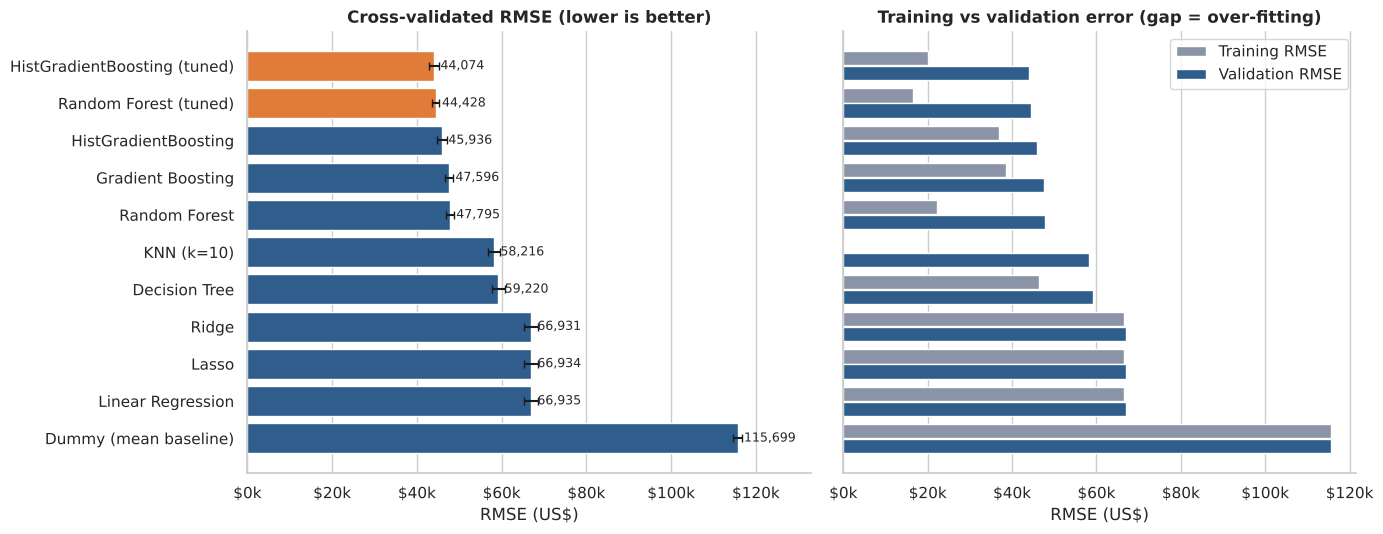

In [20]:
plot_df = cv_results.iloc[::-1].reset_index(drop=True)   # best model at the top of the chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
colors = [ACCENT2 if "tuned" in m else ACCENT for m in plot_df["Model"]]
axes[0].barh(plot_df["Model"], plot_df["CV RMSE"], xerr=plot_df["CV RMSE std"], color=colors, capsize=3)
axes[0].set(title="Cross-validated RMSE (lower is better)", xlabel="RMSE (US$)")
axes[0].xaxis.set_major_formatter(USD_K)
for i, v in enumerate(plot_df["CV RMSE"]):
    axes[0].text(v + 1500, i, f"{v:,.0f}", va="center", fontsize=9)
axes[0].set_xlim(0, plot_df["CV RMSE"].max() * 1.15)

idx = np.arange(len(plot_df))
axes[1].barh(idx + 0.2, plot_df["Train RMSE"], height=0.38, color=MUTED, label="Training RMSE")
axes[1].barh(idx - 0.2, plot_df["CV RMSE"], height=0.38, color=ACCENT, label="Validation RMSE")
axes[1].set_yticks(idx)
axes[1].set_yticklabels([])
axes[1].set(title="Training vs validation error (gap = over-fitting)", xlabel="RMSE (US$)")
axes[1].xaxis.set_major_formatter(USD_K)
axes[1].legend(loc="upper right")
grid_on(axes[0], "x")
grid_on(axes[1], "x")
save_fig("fig08_model_comparison")

## 11. Final evaluation on the untouched test set

The final model is the **tuned model with the lowest cross-validated RMSE**. The test set is used exactly once, to estimate how
the model will perform on new, unseen block groups.

In [21]:
def regression_report(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
        "Median AE": median_absolute_error(y_true, y_pred),
    }


tuned_cv = cv_results[cv_results["Model"].isin(tuned_models)].sort_values("CV RMSE")
final_name = tuned_cv.iloc[0]["Model"]
final_model = clone(tuned_models[final_name]).fit(X_train, y_train)
print(f"Selected final model: {final_name}")

# Reference points: dummy baseline and plain linear regression, fitted on the same training data
baseline = build_pipeline(DummyRegressor(strategy="mean")).fit(X_train, y_train)
linear = build_pipeline(LinearRegression()).fit(X_train, y_train)

y_pred = final_model.predict(X_test)
test_metrics = pd.DataFrame({
    "Dummy baseline": regression_report(y_test, baseline.predict(X_test)),
    "Linear Regression": regression_report(y_test, linear.predict(X_test)),
    f"{final_name}": regression_report(y_test, y_pred),
}).T
test_metrics.to_csv(OUT_DIR / "test_metrics.csv")
display(test_metrics.round(3))

final_rep = test_metrics.loc[final_name]
print(f"\nOn unseen data the final model is off by about ${final_rep['MAE']:,.0f} on average (MAE), "
      f"explains {final_rep['R2']:.1%} of the variance in house values (R2), "
      f"and has a typical percentage error of {final_rep['MAPE_%']:.1f}%.")

Selected final model: HistGradientBoosting (tuned)


,MAE,RMSE,R2,MAPE_%,Median AE
Dummy baseline,90806.788,114165.270,-0.000,63.030,77805.322
Linear Regression,47390.071,64886.689,0.677,27.719,36418.229
HistGradientBoosting (tuned),27329.044,41718.176,0.866,15.242,17148.036



On unseen data the final model is off by about $27,329 on average (MAE), explains 86.6% of the variance in house values (R2), and has a typical percentage error of 15.2%.


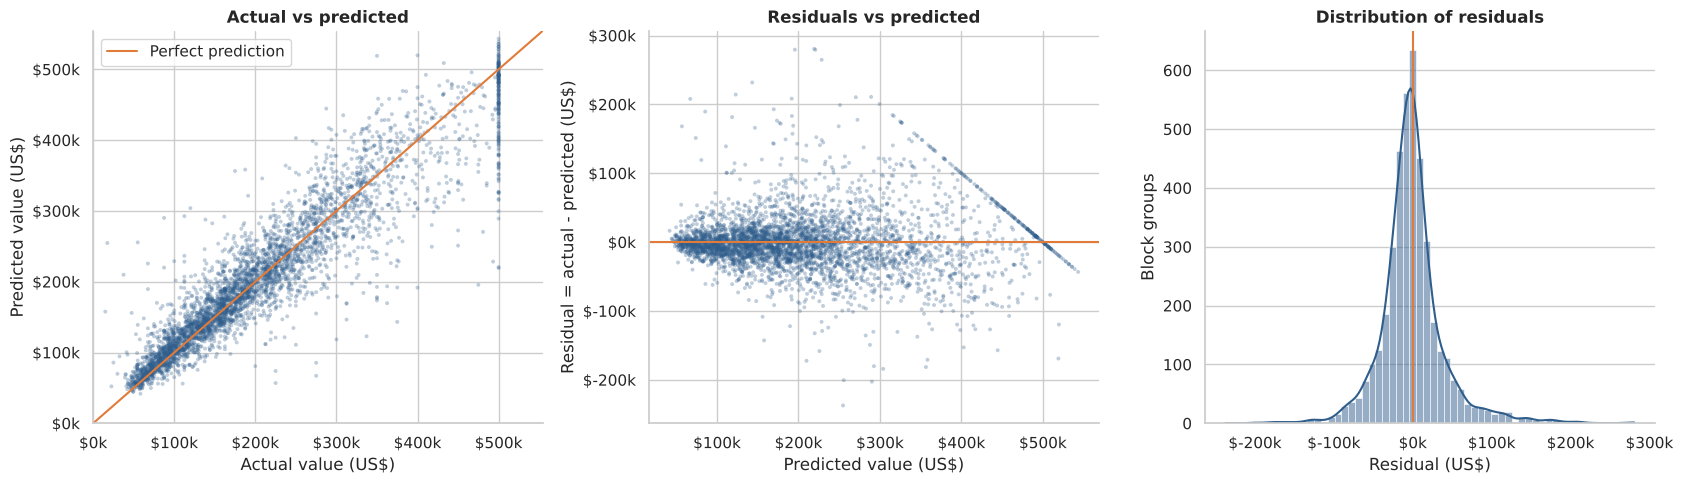

In [22]:
residuals = y_test.values - y_pred
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test, y_pred, s=8, alpha=0.3, color=ACCENT, edgecolor="none")
lims = [0, max(y_test.max(), y_pred.max()) * 1.02]
axes[0].plot(lims, lims, color=ACCENT2, lw=1.5, label="Perfect prediction")
axes[0].set(title="Actual vs predicted", xlabel="Actual value (US$)", ylabel="Predicted value (US$)", xlim=lims, ylim=lims)
axes[0].legend(loc="upper left")
for a in axes[:2]:
    a.xaxis.set_major_formatter(USD_K)
    a.yaxis.set_major_formatter(USD_K)

axes[1].scatter(y_pred, residuals, s=8, alpha=0.3, color=ACCENT, edgecolor="none")
axes[1].axhline(0, color=ACCENT2, lw=1.5)
axes[1].set(title="Residuals vs predicted", xlabel="Predicted value (US$)", ylabel="Residual = actual - predicted (US$)")

sns.histplot(residuals, bins=60, kde=True, color=ACCENT, ax=axes[2])
axes[2].axvline(0, color=ACCENT2, lw=1.5)
axes[2].set(title="Distribution of residuals", xlabel="Residual (US$)", ylabel="Block groups")
axes[2].xaxis.set_major_formatter(USD_K)
grid_on(axes[2], "y")
save_fig("fig09_actual_vs_predicted_residuals")

**Reading the plots.** Points hug the diagonal in the left panel, so predictions are well calibrated across most of the price range.
The vertical column of points at an actual value of 500,001 and the straight diagonal streak in the middle panel are **not model
failures** - they are the survey's price cap: every capped district has the same "actual" value, so its residual falls on a straight
line. The residual histogram is centred on zero and roughly symmetric.

## 12. Error analysis - where does the model struggle?

Error by ocean proximity (bias = mean(pred - actual); negative = under-prediction)


,districts,MAE,MAPE_pct,bias
ocean_proximity,,,,
<1H OCEAN,1859,29045.4,13.6,230.7
INLAND,1289,19606.8,17.4,699.6
ISLAND,3,90950.6,23.1,-39074.4
NEAR BAY,443,31483.7,14.0,3047.6
NEAR OCEAN,534,36190.2,16.6,-1262.8


Error by actual price quintile


,districts,MAE,MAPE_pct,bias
price_band,,,,
Q1 (cheapest),826,16091.9,24.3,11954.5
Q2,825,19349.7,14.9,8654.2
Q3,827,22369.0,12.4,7346.9
Q4,824,30542.0,12.3,-2402.0
Q5 (priciest),826,48296.7,12.4,-23270.8



Test rows excluding the 179 capped districts -> MAE = $26,149, RMSE = $39,371, R2 = 0.837


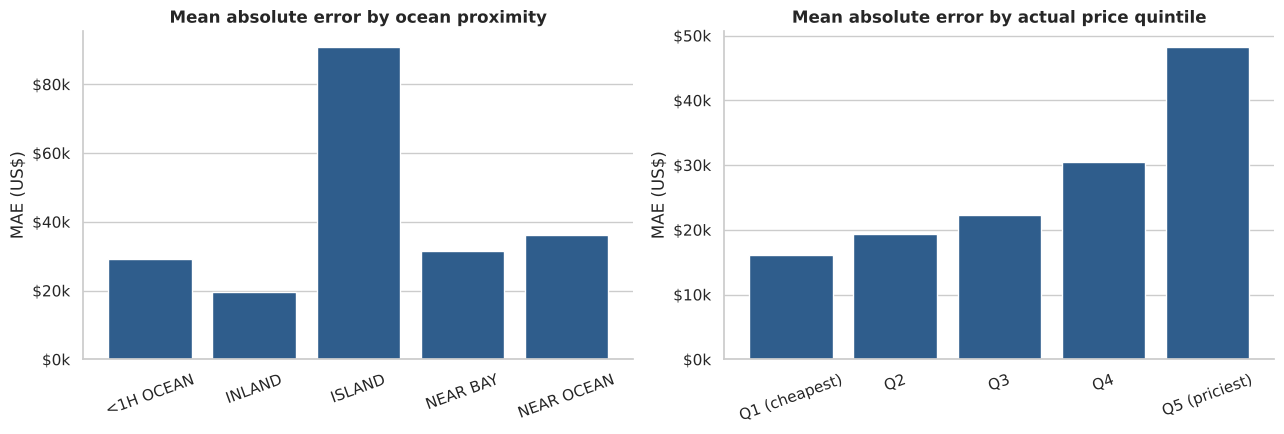

In [23]:
err = X_test.copy()
err["actual"] = y_test.values
err["pred"] = y_pred
err["error"] = err["pred"] - err["actual"]
err["abs_error"] = err["error"].abs()
err["ape_%"] = err["abs_error"] / err["actual"] * 100

by_ocean = (err.groupby("ocean_proximity")
               .agg(districts=("actual", "size"), MAE=("abs_error", "mean"), MAPE_pct=("ape_%", "mean"), bias=("error", "mean"))
               .round(1))
err["price_band"] = pd.qcut(err["actual"], 5, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4", "Q5 (priciest)"])
by_band = (err.groupby("price_band", observed=True)
              .agg(districts=("actual", "size"), MAE=("abs_error", "mean"), MAPE_pct=("ape_%", "mean"), bias=("error", "mean"))
              .round(1))
by_ocean.to_csv(OUT_DIR / "error_by_ocean_proximity.csv")
by_band.to_csv(OUT_DIR / "error_by_price_band.csv")
print("Error by ocean proximity (bias = mean(pred - actual); negative = under-prediction)")
display(by_ocean)
print("Error by actual price quintile")
display(by_band)

# Sensitivity to the censored target (rows capped at 500,001)
uncapped_mask = (y_test < cap_value).values
rep_uncapped = regression_report(y_test[uncapped_mask], y_pred[uncapped_mask])
print(f"\nTest rows excluding the {int((~uncapped_mask).sum())} capped districts -> "
      f"MAE = ${rep_uncapped['MAE']:,.0f}, RMSE = ${rep_uncapped['RMSE']:,.0f}, R2 = {rep_uncapped['R2']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(by_ocean.index, by_ocean["MAE"], color=ACCENT)
axes[0].set(title="Mean absolute error by ocean proximity", ylabel="MAE (US$)")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(by_band.index.astype(str), by_band["MAE"], color=ACCENT)
axes[1].set(title="Mean absolute error by actual price quintile", ylabel="MAE (US$)")
axes[1].tick_params(axis="x", rotation=20)
for a in axes:
    a.yaxis.set_major_formatter(USD_K)
    grid_on(a, "y")
save_fig("fig10_error_analysis")

## 13. Model interpretation - what drives the predictions?

**Permutation importance** measures how much the test-set error grows when one feature's values are randomly shuffled: the more
the error rises, the more the model relied on that feature. It works for any model and respects feature correlations better
than impurity-based importances.

,feature,importance_rmse_increase,std
0,latitude,36004.2,557.5
1,longitude,33725.6,764.9
2,median_income,31959.3,657.9
3,population_per_household,15916.6,327.0
4,ocean_proximity,13731.4,408.8
5,dist_los_angeles_km,11193.3,307.9
6,dist_san_jose_km,7424.1,232.1
7,dist_sacramento_km,6556.0,132.1
8,dist_nearest_major_city_km,6389.4,248.9
9,rooms_per_household,6100.2,356.0


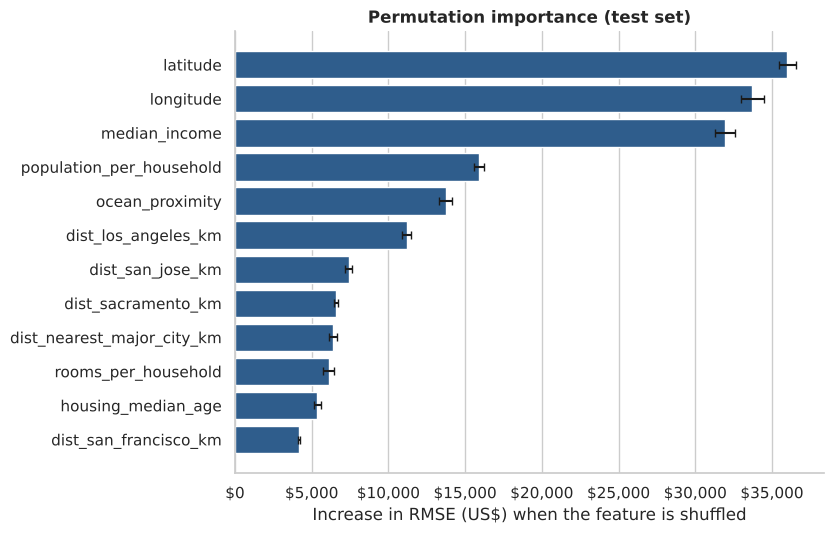

In [24]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
importance = (pd.DataFrame({"feature": X_test.columns, "importance_rmse_increase": perm.importances_mean,
                            "std": perm.importances_std})
                .sort_values("importance_rmse_increase", ascending=False).reset_index(drop=True))
importance.to_csv(OUT_DIR / "permutation_importance.csv", index=False)
display(importance.round(1).head(10))

top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top["feature"], top["importance_rmse_increase"], xerr=top["std"], color=ACCENT, capsize=3)
ax.set(title="Permutation importance (test set)", xlabel="Increase in RMSE (US$) when the feature is shuffled")
ax.xaxis.set_major_formatter(USD)
grid_on(ax, "x")
save_fig("fig11_permutation_importance")

**Partial dependence** shows the average effect of one feature on the predicted price while all other features are held as observed.

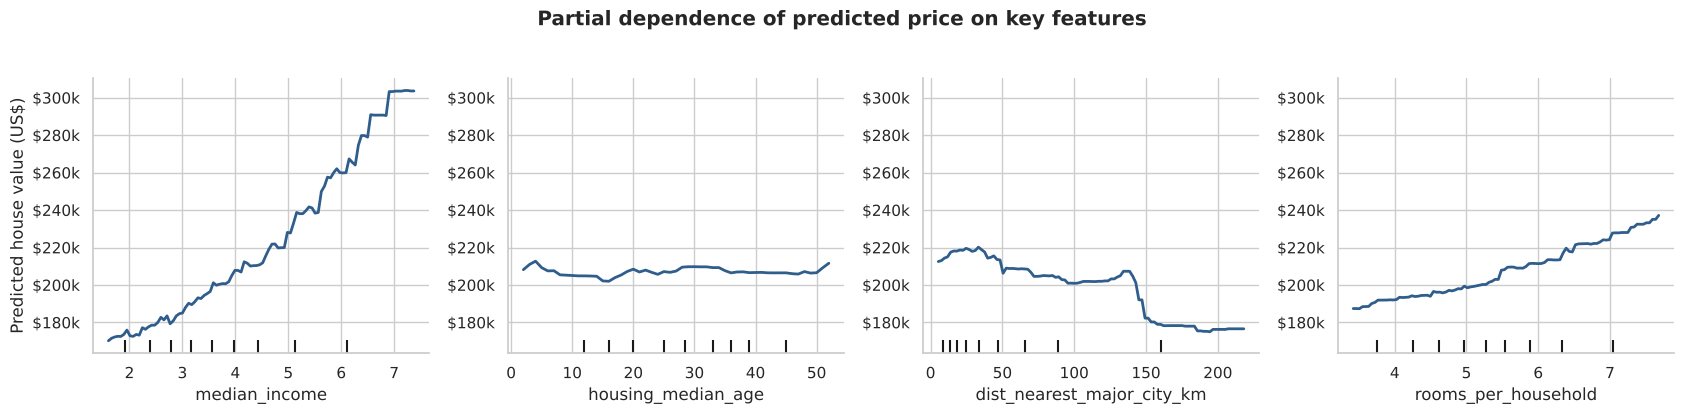

In [25]:
pd_features = ["median_income", "housing_median_age", "dist_nearest_major_city_km", "rooms_per_household"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
PartialDependenceDisplay.from_estimator(final_model, X_train.sample(min(2500, len(X_train)), random_state=RANDOM_STATE), pd_features,
                                        kind="average", ax=axes, line_kw={"color": ACCENT, "linewidth": 2})
for ax in axes:
    ax.set_ylabel("")
    ax.yaxis.set_major_formatter(USD_K)
axes[0].set_ylabel("Predicted house value (US$)")
fig.suptitle("Partial dependence of predicted price on key features", fontweight="bold", y=1.03)
save_fig("fig12_partial_dependence")

## 14. Save the model and make predictions on new data

The saved object is the **complete pipeline** (imputer + scaler + encoder + model). New data only needs the nine raw columns;
`add_features()` creates the engineered features before prediction.

In [26]:
MODEL_PATH = OUT_DIR / "house_price_model.joblib"
joblib.dump(final_model, MODEL_PATH)
print(f"Model saved to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

# Round-trip check: the reloaded model must give identical predictions
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(X_test), y_pred), "Reloaded model gives different predictions!"
print("Reload check passed - predictions are identical.")


def predict_house_price(raw_df):
    """Predict median house value (US$) for raw block-group data (the 9 original columns, without the target)."""
    return reloaded.predict(add_features(raw_df))


new_districts = pd.DataFrame([
    {"longitude": -118.30, "latitude": 34.05, "housing_median_age": 30, "total_rooms": 3200, "total_bedrooms": 650,
     "population": 1500, "households": 580, "median_income": 4.5, "ocean_proximity": "<1H OCEAN"},
    {"longitude": -122.25, "latitude": 37.85, "housing_median_age": 40, "total_rooms": 2100, "total_bedrooms": 420,
     "population": 900, "households": 400, "median_income": 7.8, "ocean_proximity": "NEAR BAY"},
    {"longitude": -119.77, "latitude": 36.74, "housing_median_age": 20, "total_rooms": 2800, "total_bedrooms": 560,
     "population": 1900, "households": 520, "median_income": 2.6, "ocean_proximity": "INLAND"},
], index=["Los Angeles area", "Bay Area (near bay)", "Central Valley (inland)"])

demo = new_districts[["median_income", "ocean_proximity"]].copy()
demo["predicted_value_US$"] = predict_house_price(new_districts).round(0)
display(demo)

Model saved to outputs/house_price_model.joblib (2.9 MB)
Reload check passed - predictions are identical.


,median_income,ocean_proximity,predicted_value_US$
Los Angeles area,4.5,<1H OCEAN,298876.0
Bay Area (near bay),7.8,NEAR BAY,409735.0
Central Valley (inland),2.6,INLAND,73922.0


## 15. Summary and conclusions

In [27]:
best_cv = cv_results.iloc[0]
lin_cv = cv_results[cv_results["Model"] == "Linear Regression"].iloc[0]
base_cv = cv_results[cv_results["Model"] == "Dummy (mean baseline)"].iloc[0]
top3 = ", ".join(importance["feature"].head(3))

print("PROJECT SUMMARY")
print("=" * 70)
print(f"Dataset                 : {len(df):,} California block groups, {df.shape[1] - 1} raw features")
print(f"Engineered features     : {len(NEW_FEATURES)}")
print(f"Best model (CV)         : {best_cv['Model']}  (RMSE {best_cv['CV RMSE']:,.0f}, R2 {best_cv['CV R2']:.3f})")
print(f"Final model             : {final_name}")
print(f"Test RMSE / MAE / R2    : ${final_rep['RMSE']:,.0f} / ${final_rep['MAE']:,.0f} / {final_rep['R2']:.3f}")
print(f"Test MAPE               : {final_rep['MAPE_%']:.1f}%")
print(f"Improvement vs baseline : RMSE reduced by {1 - final_rep['RMSE'] / test_metrics.loc['Dummy baseline', 'RMSE']:.0%}")
print(f"Improvement vs linear   : RMSE reduced by {1 - final_rep['RMSE'] / test_metrics.loc['Linear Regression', 'RMSE']:.0%}")
print(f"Top 3 price drivers     : {top3}")

summary = {
    "dataset": {"rows": int(len(df)), "raw_features": int(df.shape[1] - 1), "engineered_features": len(NEW_FEATURES),
                "missing_total_bedrooms": int(df["total_bedrooms"].isna().sum()),
                "capped_target_rows": n_capped_target, "capped_age_rows": n_capped_age,
                "duplicates": int(df.duplicated().sum()),
                "target_mean": float(df[TARGET].mean()), "target_median": float(df[TARGET].median()),
                "target_skew": float(df[TARGET].skew()), "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
                "corr_with_target": {k: float(v) for k, v in target_corr.items()}},
    "final_model": final_name,
    "best_params": {k.replace("model__", ""): (v if v is None or isinstance(v, (str, int)) else float(v))
                    for k, v in (hgb_search if "HistGradient" in final_name else rf_search).best_params_.items()},
    "test_metrics": {k: {m: float(v) for m, v in r.items()} for k, r in test_metrics.iterrows()},
    "test_metrics_excluding_capped": {k: float(v) for k, v in rep_uncapped.items()},
    "capped_test_rows": int((~uncapped_mask).sum()),
    "top_features": importance.head(10)[["feature", "importance_rmse_increase"]].to_dict("records"),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__},
    "random_state": RANDOM_STATE, "fast_mode": FAST_MODE,
}
with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nAll tables, figures and the model were saved to ./outputs and ./figures")

PROJECT SUMMARY
Dataset                 : 20,640 California block groups, 9 raw features
Engineered features     : 9
Best model (CV)         : HistGradientBoosting (tuned)  (RMSE 44,074, R2 0.855)
Final model             : HistGradientBoosting (tuned)
Test RMSE / MAE / R2    : $41,718 / $27,329 / 0.866
Test MAPE               : 15.2%
Improvement vs baseline : RMSE reduced by 63%
Improvement vs linear   : RMSE reduced by 36%
Top 3 price drivers     : latitude, longitude, median_income

All tables, figures and the model were saved to ./outputs and ./figures


### Conclusions

1. **Machine learning clearly beats simple approaches.** Non-linear ensemble models (especially gradient boosting and random
   forests) are far more accurate than linear regression, which in turn is far better than predicting the average.
2. **Location and income dominate.** Median income and geographic position (latitude, longitude and distance to major cities / the
   coast) explain most of the price differences; engineered distance features add value on top of raw coordinates.
3. **The pipeline is leak-free and reproducible.** Imputation, scaling and encoding are learned only from training folds, the
   test set is used once, and a fixed random seed makes the results repeatable.
4. **The model is usable.** The saved pipeline can score new block groups from the nine raw columns.

### Limitations

* The data are from the **1990 census** - absolute price levels and relationships have changed; the *method* transfers, the *numbers* do not.
* `median_house_value` is **capped at $500,001**, so the model cannot learn true values of the most expensive areas and tends to
  under-predict them (see the error analysis by price band).
* Records are **block-group aggregates**, not individual houses; features such as condition, lot size, school quality or
  crime are not available.
* Spatial autocorrelation: neighbouring block groups are similar, so random splits can be slightly optimistic compared with
  predicting a completely new region.

### Future work

* Add external features (distance to coastline, school ratings, crime, transport) and more recent data.
* Try target transformation (log), stacking / blending, and gradient-boosting libraries such as XGBoost or LightGBM.
* Use **spatial cross-validation** (hold out whole regions) for a more honest estimate of generalisation.
* Add model explanations with SHAP values and deploy the model as a Streamlit / Flask web app or API.